# 📱 Smartphone Human Activity Recognition (HAR)
### Comparative Predictive Modeling Study — KDD Process

---

### 🎯 Research Objective
Classify physical human activities using raw and pre-engineered smartphone accelerometer and gyroscope signals. We conduct **two separate benchmark experiments** to evaluate and compare multiple machine learning algorithms:

*   **Experiment 1 (UCI HAR 240):** Basic activities with 6 balanced classes.
*   **Experiment 2 (UCI HAPT 341):** Extended activities containing 12 classes (including brief, challenging postural transitions).

---

### 🔬 KDD Methodology Workflow
1. **Data Selection:** Target specific datasets from the UCI Machine Learning Repository.
2. **Data Understanding:** Audit class frequencies, dimensions, and potential label imbalances.
3. **Data Preprocessing & Scaling:** Standardize feature variations dynamically within scikit-learn Pipelines to avoid target leakage.
4. **Data Mining:** Benchmark **Logistic Regression**, **k-NN**, **Decision Trees**, and **Random Forests**.
5. **Evaluation:** Compare validation split performance using **Macro F1 Score** and test the best-selected champion on unseen test splits.
6. **Knowledge Presentation:** Interpret predictions with confusion matrices and study Gini importance.

## 1. Setup — KDD: project preparation

In [34]:
import os
import re
import time
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
BASE_DIR = Path("/content/har_project")
BASE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
print("Setup complete. Working directory:", BASE_DIR)


Setup complete. Working directory: /content/har_project


## 2. Data collection — KDD: Selection

We download the official UCI ZIP files and use the pre-extracted feature matrices with their official train/test partitions. Dataset 240 uses six activity classes. Dataset 341 includes postural transitions in addition to basic activities.

In [35]:
DATASETS = {
    "UCI_HAR_240": {
        "url": "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip",
        "zip_path": BASE_DIR / "uci_har_240.zip",
        "extract_dir": BASE_DIR / "uci_har_240"
    },
    "UCI_HAPT_341": {
        "url": "https://archive.ics.uci.edu/static/public/341/smartphone+based+recognition+of+human+activities+and+postural+transitions.zip",
        "zip_path": BASE_DIR / "uci_hapt_341.zip",
        "extract_dir": BASE_DIR / "uci_hapt_341"
    }
}

def download_and_extract(config):
    extract_dir = config["extract_dir"]
    zip_path = config["zip_path"]

    # Always perform the download if the target directory doesn't have text files
    if not extract_dir.exists() or not any(extract_dir.rglob("*.txt")):
        if not zip_path.exists():
            print(f"Downloading {zip_path.name} ...")
            urllib.request.urlretrieve(config["url"], zip_path)
        extract_dir.mkdir(parents=True, exist_ok=True)
        print(f"Extracting {zip_path.name} ...")
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(extract_dir)

        # Unzip any nested zip files (e.g., 'UCI HAR Dataset.zip' inside uci_har_240)
        for nested_zip in list(extract_dir.rglob("*.zip")):
            print(f"Extracting nested archive {nested_zip.name} ...")
            with zipfile.ZipFile(nested_zip, "r") as nzf:
                nzf.extractall(extract_dir)
    else:
        print(f"Using existing extracted files: {extract_dir}")
    return extract_dir

for name, cfg in DATASETS.items():
    try:
        download_and_extract(cfg)
        print(name, "ready")
    except Exception as exc:
        print(f"Could not download/extract {name}: {exc}")

Using existing extracted files: /content/har_project/uci_har_240
UCI_HAR_240 ready
Using existing extracted files: /content/har_project/uci_hapt_341
UCI_HAPT_341 ready


## 3. Data loading — KDD: Data understanding

The loader locates `X_train.txt`, `y_train.txt`, `X_test.txt`, and `y_test.txt` inside each extracted archive. It also looks for `features.txt` and `activity_labels.txt` to label columns and classes. If file names or folders differ in the downloaded archive, the diagnostic output will help identify the structure.

In [36]:
def find_file(root, filename):
    matches = [p for p in Path(root).rglob("*") if p.is_file() and p.name.lower() == filename.lower()]
    return matches[0] if matches else None

def read_whitespace_matrix(path):
    # UCI text matrices are whitespace-separated and have no header.
    return pd.read_csv(path, sep=r"\s+", header=None, engine="python")

def load_uci_split_dataset(extract_dir, dataset_name):
    root = Path(extract_dir)
    x_train_path = find_file(root, "X_train.txt")
    y_train_path = find_file(root, "y_train.txt")
    x_test_path = find_file(root, "X_test.txt")
    y_test_path = find_file(root, "y_test.txt")

    required = {
        "X_train.txt": x_train_path, "y_train.txt": y_train_path,
        "X_test.txt": x_test_path, "y_test.txt": y_test_path
    }
    missing = [k for k, v in required.items() if v is None]
    if missing:
        print(f"Files found under {root}:")
        for p in list(root.rglob("*.txt"))[:40]:
            print(" -", p.relative_to(root))
        raise FileNotFoundError(f"{dataset_name}: required files not found: {missing}")

    X_train = read_whitespace_matrix(x_train_path)
    y_train = read_whitespace_matrix(y_train_path).iloc[:, 0]
    X_test = read_whitespace_matrix(x_test_path)
    y_test = read_whitespace_matrix(y_test_path).iloc[:, 0]

    features_path = find_file(root, "features.txt")
    if features_path is not None:
        features_df = pd.read_csv(features_path, sep=r"\s+", header=None, engine="python")
        # Standard UCI HAR features.txt: first column is index, second is feature name.
        if features_df.shape[1] >= 2 and len(features_df) == X_train.shape[1]:
            feature_names = features_df.iloc[:, 1].astype(str).tolist()
        elif len(features_df) == X_train.shape[1]:
            feature_names = features_df.iloc[:, -1].astype(str).tolist()
        else:
            feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
    else:
        feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]

    # Make feature names unique to avoid duplicate-column issues in downstream plots.
    seen = {}
    unique_names = []
    for name in feature_names:
        count = seen.get(name, 0)
        seen[name] = count + 1
        unique_names.append(name if count == 0 else f"{name}_{count}")
    X_train.columns = unique_names
    X_test.columns = unique_names

    # Map numeric labels to readable activity names if the official mapping is present.
    labels_path = find_file(root, "activity_labels.txt")
    label_map = {}
    if labels_path is not None:
        labels_df = pd.read_csv(labels_path, sep=r"\s+", header=None, engine="python")
        if labels_df.shape[1] >= 2:
            label_map = dict(zip(labels_df.iloc[:, 0].astype(int), labels_df.iloc[:, 1].astype(str)))

    # Convert label IDs to names where a mapping is available; otherwise retain original labels.
    if label_map:
        y_train = y_train.astype(int).map(lambda v: label_map.get(v, str(v)))
        y_test = y_test.astype(int).map(lambda v: label_map.get(v, str(v)))
    else:
        y_train = y_train.astype(str)
        y_test = y_test.astype(str)

    # Ensure train and test have the same feature count and names.
    if X_train.shape[1] != X_test.shape[1]:
        raise ValueError(f"{dataset_name}: train/test feature count mismatch")

    return {
        "name": dataset_name,
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test,
        "label_map": label_map
    }

loaded = {}
for name, cfg in DATASETS.items():
    try:
        loaded[name] = load_uci_split_dataset(cfg["extract_dir"], name)
        d = loaded[name]
        print(f"\n{name}")
        print("Train:", d["X_train"].shape, "Test:", d["X_test"].shape)
        print("Classes:", sorted(pd.Series(d["y_train"]).unique().tolist()))
    except Exception as exc:
        print(f"\n{name} loading failed: {exc}")

if not loaded:
    raise RuntimeError("No dataset loaded successfully. Check the download and file structure before proceeding.")


UCI_HAR_240
Train: (7352, 561) Test: (2947, 561)
Classes: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']

UCI_HAPT_341
Train: (7767, 561) Test: (3162, 561)
Classes: ['LAYING', 'LIE_TO_SIT', 'LIE_TO_STAND', 'SITTING', 'SIT_TO_LIE', 'SIT_TO_STAND', 'STANDING', 'STAND_TO_LIE', 'STAND_TO_SIT', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']


In [37]:
# Print the structure of the extracted folder for UCI_HAR_240 to see where files are located.
from pathlib import Path

har_240_dir = Path("/content/har_project/uci_har_240")
print("Files found in uci_har_240:")
for p in list(har_240_dir.rglob("*"))[:30]:
    if p.is_file():
        print(" - ", p.relative_to(har_240_dir))

Files found in uci_har_240:
 -  UCI HAR Dataset.zip
 -  UCI HAR Dataset.names
 -  UCI HAR Dataset/README.txt
 -  UCI HAR Dataset/.DS_Store
 -  UCI HAR Dataset/activity_labels.txt
 -  UCI HAR Dataset/features.txt
 -  UCI HAR Dataset/features_info.txt
 -  __MACOSX/._UCI HAR Dataset
 -  __MACOSX/UCI HAR Dataset/._test
 -  __MACOSX/UCI HAR Dataset/._features.txt
 -  __MACOSX/UCI HAR Dataset/._activity_labels.txt
 -  __MACOSX/UCI HAR Dataset/._README.txt
 -  __MACOSX/UCI HAR Dataset/._features_info.txt
 -  __MACOSX/UCI HAR Dataset/._.DS_Store
 -  __MACOSX/UCI HAR Dataset/._train
 -  __MACOSX/UCI HAR Dataset/train/._Inertial Signals
 -  __MACOSX/UCI HAR Dataset/train/._X_train.txt
 -  __MACOSX/UCI HAR Dataset/train/._subject_train.txt
 -  __MACOSX/UCI HAR Dataset/train/._y_train.txt
 -  __MACOSX/UCI HAR Dataset/test/._y_test.txt
 -  __MACOSX/UCI HAR Dataset/test/._subject_test.txt


## 4. Initial data audit — KDD: Data understanding

We inspect shapes, data types, missing values, duplicate rows, and activity counts. Duplicate feature rows are reported but not automatically removed: identical sensor windows can be legitimate observations.

In [38]:
audit_rows = []
for name, d in loaded.items():
    Xtr, Xte = d["X_train"], d["X_test"]
    ytr, yte = d["y_train"], d["y_test"]
    audit_rows.append({
        "dataset": name,
        "train_rows": len(Xtr),
        "test_rows": len(Xte),
        "features": Xtr.shape[1],
        "train_classes": ytr.nunique(),
        "test_classes": yte.nunique(),
        "missing_train_cells": int(Xtr.isna().sum().sum()),
        "missing_test_cells": int(Xte.isna().sum().sum()),
        "duplicate_train_feature_rows": int(Xtr.duplicated().sum())
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

for name, d in loaded.items():
    print("\n", name, "— training class distribution")
    display(d["y_train"].value_counts().rename_axis("activity").reset_index(name="count"))


,dataset,train_rows,test_rows,features,train_classes,test_classes,missing_train_cells,missing_test_cells,duplicate_train_feature_rows
0,UCI_HAR_240,7352,2947,561,6,6,0,0,0
1,UCI_HAPT_341,7767,3162,561,12,12,0,0,0



 UCI_HAR_240 — training class distribution


,activity,count
0,LAYING,1407
1,STANDING,1374
2,SITTING,1286
3,WALKING,1226
4,WALKING_UPSTAIRS,1073
5,WALKING_DOWNSTAIRS,986



 UCI_HAPT_341 — training class distribution


,activity,count
0,STANDING,1423
1,LAYING,1413
2,SITTING,1293
3,WALKING,1226
4,WALKING_UPSTAIRS,1073
5,WALKING_DOWNSTAIRS,987
6,STAND_TO_LIE,90
7,SIT_TO_LIE,75
8,LIE_TO_SIT,60
9,LIE_TO_STAND,57


## 5. Exploratory data analysis — KDD: Data understanding

Plot class balance for each dataset. The labels are activity categories, not continuous numerical outcomes, so this is a multiclass classification task.

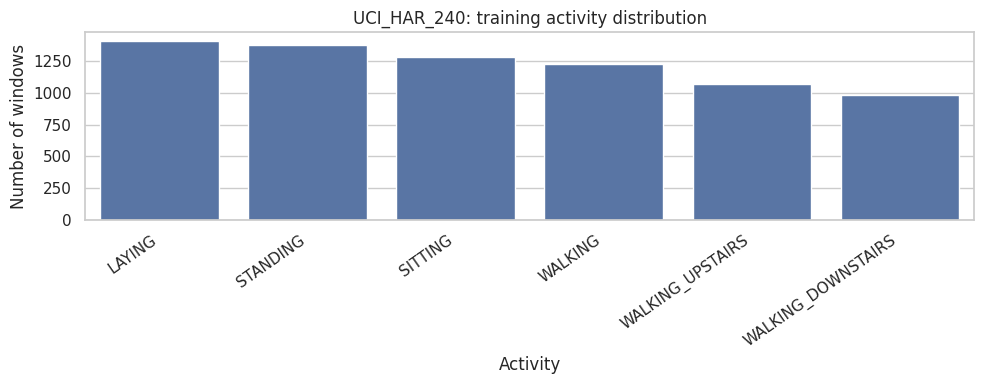

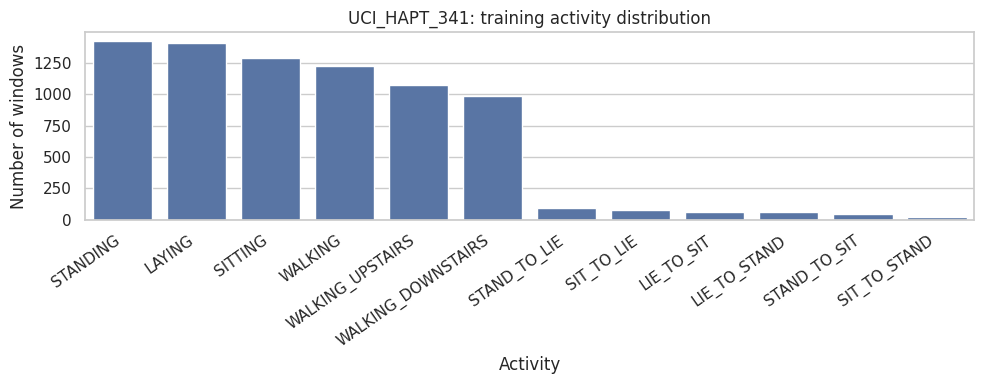

,count,mean,std,min,25%,50%,75%,max
tBodyAcc-mean()-X,7352.0,0.274488,0.070261,-1.000000,0.262975,0.277193,0.288461,1.000000
tBodyAcc-mean()-Y,7352.0,-0.017695,0.040811,-1.000000,-0.024863,-0.017219,-0.010783,1.000000
tBodyAcc-mean()-Z,7352.0,-0.109141,0.056635,-1.000000,-0.120993,-0.108676,-0.097794,1.000000
tBodyAcc-std()-X,7352.0,-0.605438,0.448734,-1.000000,-0.992754,-0.946196,-0.242813,1.000000
tBodyAcc-std()-Y,7352.0,-0.510938,0.502645,-0.999873,-0.978129,-0.851897,-0.034231,0.916238
tBodyAcc-std()-Z,7352.0,-0.604754,0.418687,-1.000000,-0.980233,-0.859365,-0.262415,1.000000
tBodyAcc-mad()-X,7352.0,-0.630512,0.424073,-1.000000,-0.993591,-0.950709,-0.292680,1.000000
tBodyAcc-mad()-Y,7352.0,-0.526907,0.485942,-1.000000,-0.978162,-0.857328,-0.066701,0.967664
tBodyAcc-mad()-Z,7352.0,-0.606150,0.414122,-1.000000,-0.980251,-0.857143,-0.265671,1.000000
tBodyAcc-max()-X,7352.0,-0.468604,0.544547,-1.000000,-0.936219,-0.881637,-0.017129,1.000000


In [39]:
for name, d in loaded.items():
    counts = d["y_train"].value_counts().sort_values(ascending=False)
    plt.figure(figsize=(10, 4))
    sns.barplot(x=counts.index, y=counts.values)
    plt.title(f"{name}: training activity distribution")
    plt.xlabel("Activity")
    plt.ylabel("Number of windows")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

# Inspect descriptive statistics for the first dataset.
first_name = next(iter(loaded))
display(loaded[first_name]["X_train"].describe().T.head(15))


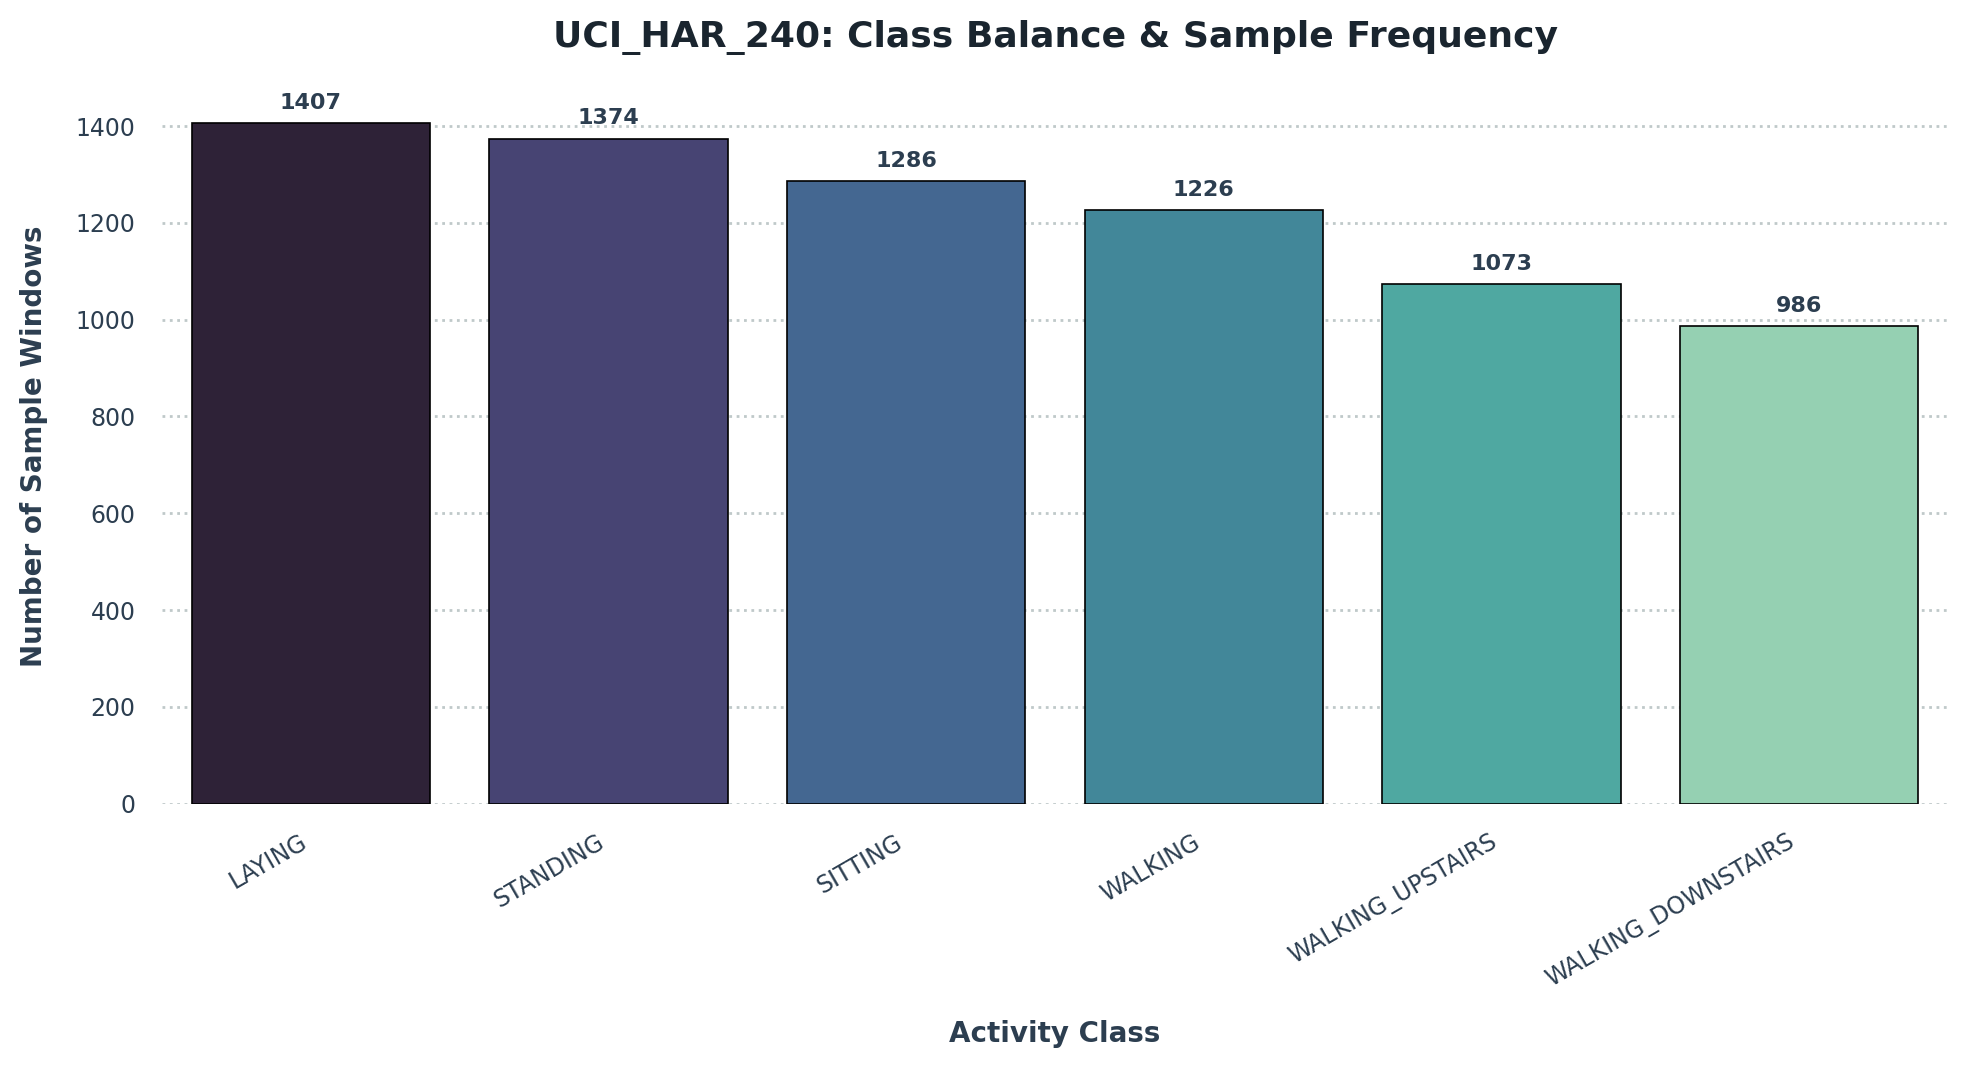

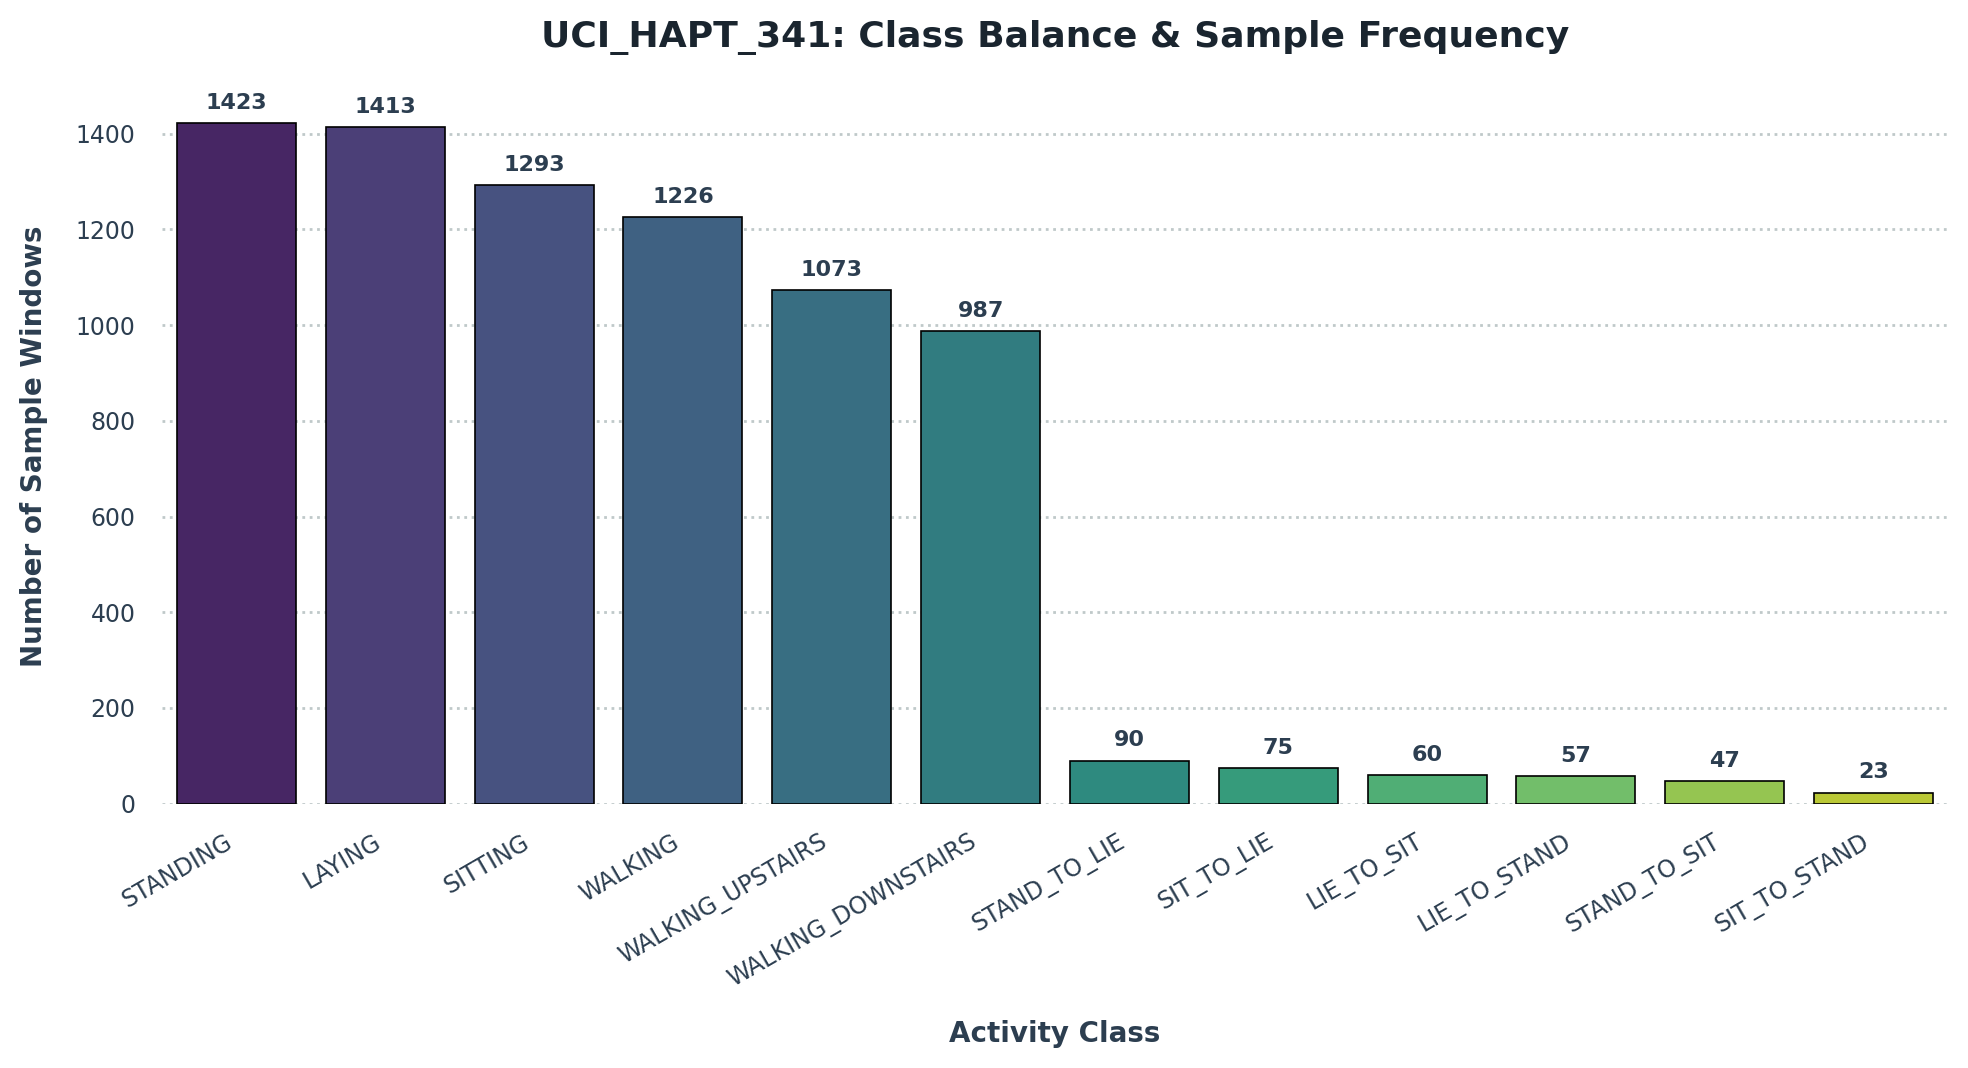

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure premium global aesthetics for presentation/report
plt.rcParams["figure.dpi"] = 200
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]

for name, d in loaded.items():
    counts = d["y_train"].value_counts().sort_values(ascending=False)

    # Use custom clean palettes for a modern aesthetic
    palette = sns.color_palette("mako", n_colors=len(counts)) if "240" in name else sns.color_palette("viridis", n_colors=len(counts))

    fig, ax = plt.subplots(figsize=(10, 5.5))

    # Avoid FutureWarning by explicitly mapping 'hue' and setting 'legend=False'
    bars = sns.barplot(
        x=counts.index,
        y=counts.values,
        hue=counts.index,
        palette=palette,
        ax=ax,
        edgecolor="black",
        linewidth=0.6,
        legend=False
    )

    # Add polished numerical labels above the bars
    for bar in bars.patches:
        yval = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2.0,
            yval + (counts.max() * 0.015),
            f'{int(yval)}',
            ha='center',
            va='bottom',
            fontsize=8,
            fontweight='bold',
            color='#2c3e50'
        )

    ax.set_title(f"{name}: Class Balance & Sample Frequency", fontsize=13, fontweight="bold", pad=15, color="#1a252f")
    ax.set_xlabel("Activity Class", fontsize=10, labelpad=10, fontweight="bold", color="#2c3e50")
    ax.set_ylabel("Number of Sample Windows", fontsize=10, labelpad=10, fontweight="bold", color="#2c3e50")

    plt.xticks(rotation=30, ha="right", fontsize=8.5, color="#2c3e50")
    plt.yticks(fontsize=8.5, color="#2c3e50")

    sns.despine(left=True, bottom=True)
    ax.grid(axis='y', linestyle=':', alpha=0.6, color='#95a5a6')

    plt.tight_layout()
    plt.show()

## 6. Preprocessing — KDD: Preprocessing and transformation

- Keep the official UCI train/test partitions.
- Create a validation split from the training partition for model selection.
- Use an imputer and scaler inside pipelines so they are fitted only on training data.
- Do not use the final test partition to choose models or tune parameters.
- No oversampling is applied by default. We will inspect class balance first; any resampling must happen only within training folds.

In [51]:
def make_models():
    return {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1500, class_weight=None, random_state=RANDOM_STATE))
        ]),
        "k-NN": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=5, weights="distance"))
        ]),
        "Decision Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight=None))
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1,
                class_weight=None, max_features="sqrt"
            ))
        ]),

    }

print("Models defined:", list(make_models().keys()))


Models defined: ['Logistic Regression', 'k-NN', 'Decision Tree', 'Random Forest']


## 7. Model development and selection — KDD: Data mining

For each dataset, split the official training partition into a model-training subset and a validation subset. Compare the five algorithms on validation macro F1 and accuracy. Macro F1 gives each class equal weight and is useful if class frequencies differ.

In [41]:
def metric_row(y_true, y_pred, model_name, dataset_name, split_name):
    return {
        "dataset": dataset_name,
        "split": split_name,
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

validation_results = []
selected_models = {}

for name, d in loaded.items():
    print(f"\n===== {name}: model selection =====")
    X_train_full, y_train_full = d["X_train"], d["y_train"]

    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y_train_full
    )

    fitted_validation_models = {}
    for model_name, model in make_models().items():
        start = time.time()
        try:
            model.fit(X_fit, y_fit)
            pred = model.predict(X_val)
            row = metric_row(y_val, pred, model_name, name, "validation")
            row["fit_seconds"] = round(time.time() - start, 2)
            validation_results.append(row)
            fitted_validation_models[model_name] = model
            print(f"{model_name:22s} | Accuracy={row['accuracy']:.4f} | Macro F1={row['f1_macro']:.4f}")
        except Exception as exc:
            print(f"{model_name} failed on {name}: {exc}")

    if not fitted_validation_models:
        print("No model succeeded for", name)
        continue

    local_rows = [r for r in validation_results if r["dataset"] == name]
    # Primary selection criterion: macro F1; tie-breaker: accuracy.
    best_row = sorted(local_rows, key=lambda r: (r["f1_macro"], r["accuracy"]), reverse=True)[0]
    selected_models[name] = best_row["model"]
    print("Selected using validation results:", best_row["model"])

validation_df = pd.DataFrame(validation_results).sort_values(
    ["dataset", "f1_macro", "accuracy"], ascending=[True, False, False]
)
display(validation_df)



===== UCI_HAR_240: model selection =====
Logistic Regression    | Accuracy=0.9857 | Macro F1=0.9868
k-NN                   | Accuracy=0.9646 | Macro F1=0.9667
Decision Tree          | Accuracy=0.9388 | Macro F1=0.9380
Random Forest          | Accuracy=0.9878 | Macro F1=0.9879
MLP Neural Network failed on UCI_HAR_240: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''
Selected using validation results: Random Forest

===== UCI_HAPT_341: model selection =====
Logistic Regression    | Accuracy=0.9704 | Macro F1=0.8402
k-NN                   | Accuracy=0.9492 | Macro F1=0.8242
Decision Tree          | Accuracy=0.8964 | Macro F1=0.7906
Random Forest          | Accuracy=0.9723 | Macro F1=0.8661
MLP Neural Network failed on UCI_HAPT_341: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''
S

,dataset,split,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds
7,UCI_HAPT_341,validation,Random Forest,0.972329,0.896596,0.845368,0.866064,33.08
4,UCI_HAPT_341,validation,Logistic Regression,0.970399,0.843143,0.850407,0.840205,7.30
5,UCI_HAPT_341,validation,k-NN,0.949163,0.840773,0.821717,0.824174,0.85
6,UCI_HAPT_341,validation,Decision Tree,0.896396,0.809990,0.780860,0.790618,8.71
3,UCI_HAR_240,validation,Random Forest,0.987763,0.987981,0.988035,0.987936,28.85
0,UCI_HAR_240,validation,Logistic Regression,0.985724,0.986847,0.986806,0.986825,6.76
1,UCI_HAR_240,validation,k-NN,0.964650,0.968962,0.965944,0.966661,0.79
2,UCI_HAR_240,validation,Decision Tree,0.938817,0.938207,0.938049,0.937979,6.23


## 8. Final evaluation — KDD: Evaluation

Retrain the selected model using the complete official training partition, then evaluate it once on the official test partition. These test metrics are the final reported estimates. Model selection was based on validation data only.

In [42]:
final_results = []
final_predictions = {}
final_fitted_models = {}

for name, d in loaded.items():
    if name not in selected_models:
        continue

    chosen_name = selected_models[name]
    model = make_models()[chosen_name]
    start = time.time()
    model.fit(d["X_train"], d["y_train"])
    y_pred = model.predict(d["X_test"])
    elapsed = time.time() - start

    row = metric_row(d["y_test"], y_pred, chosen_name, name, "official_test")
    row["fit_seconds_full_train"] = round(elapsed, 2)
    final_results.append(row)
    final_predictions[name] = y_pred
    final_fitted_models[name] = model

    print(f"\n===== {name}: final test results =====")
    print("Selected model:", chosen_name)
    print(classification_report(d["y_test"], y_pred, zero_division=0))
    print("Accuracy:", round(row["accuracy"], 4))
    print("Macro F1:", round(row["f1_macro"], 4))

final_df = pd.DataFrame(final_results)
display(final_df)



===== UCI_HAR_240: final test results =====
Selected model: Random Forest
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.92      0.89      0.90       491
          STANDING       0.90      0.92      0.91       532
           WALKING       0.90      0.97      0.93       496
WALKING_DOWNSTAIRS       0.96      0.85      0.91       420
  WALKING_UPSTAIRS       0.89      0.92      0.90       471

          accuracy                           0.93      2947
         macro avg       0.93      0.93      0.93      2947
      weighted avg       0.93      0.93      0.93      2947

Accuracy: 0.9284
Macro F1: 0.9266

===== UCI_HAPT_341: final test results =====
Selected model: Random Forest
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       545
        LIE_TO_SIT       0.66      0.76      0.70        25
      LIE_TO_STAND       0.74  

,dataset,split,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds_full_train
0,UCI_HAR_240,official_test,Random Forest,0.928402,0.929351,0.925405,0.926586,36.69
1,UCI_HAPT_341,official_test,Random Forest,0.911448,0.826434,0.825284,0.822505,43.05


## 9. Confusion matrices — KDD: Evaluation and interpretation

A confusion matrix shows which activity classes are predicted correctly and which are confused. The class order is derived from the union of actual and predicted labels.

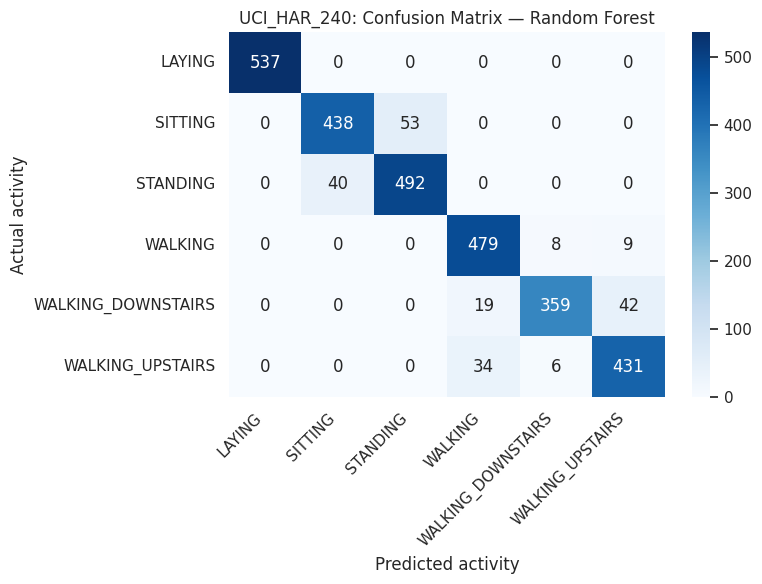

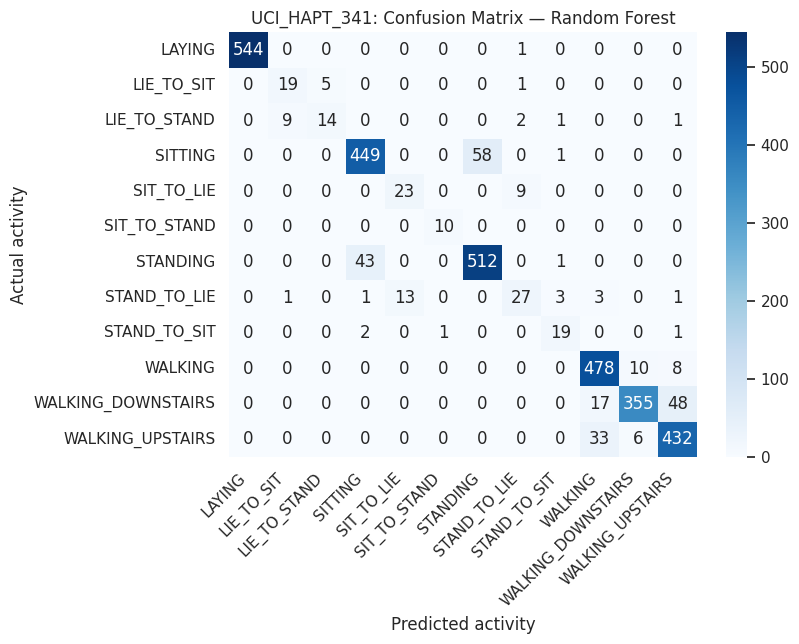

In [43]:
for name, y_pred in final_predictions.items():
    y_true = loaded[name]["y_test"]
    labels = sorted(set(pd.Series(y_true).astype(str)) | set(pd.Series(y_pred).astype(str)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    plt.figure(figsize=(max(8, len(labels) * 0.7), max(6, len(labels) * 0.55)))
    sns.heatmap(cm, annot=(len(labels) <= 12), fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"{name}: Confusion Matrix — {selected_models[name]}")
    plt.xlabel("Predicted activity")
    plt.ylabel("Actual activity")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


## 10. Feature importance — KDD: Knowledge interpretation

For tree-based models, report feature importance from the selected Random Forest or Decision Tree. If a different model is selected, we still inspect Random Forest as a separate explanatory benchmark, clearly labelling it as such. Feature importance indicates predictive contribution, not causation.

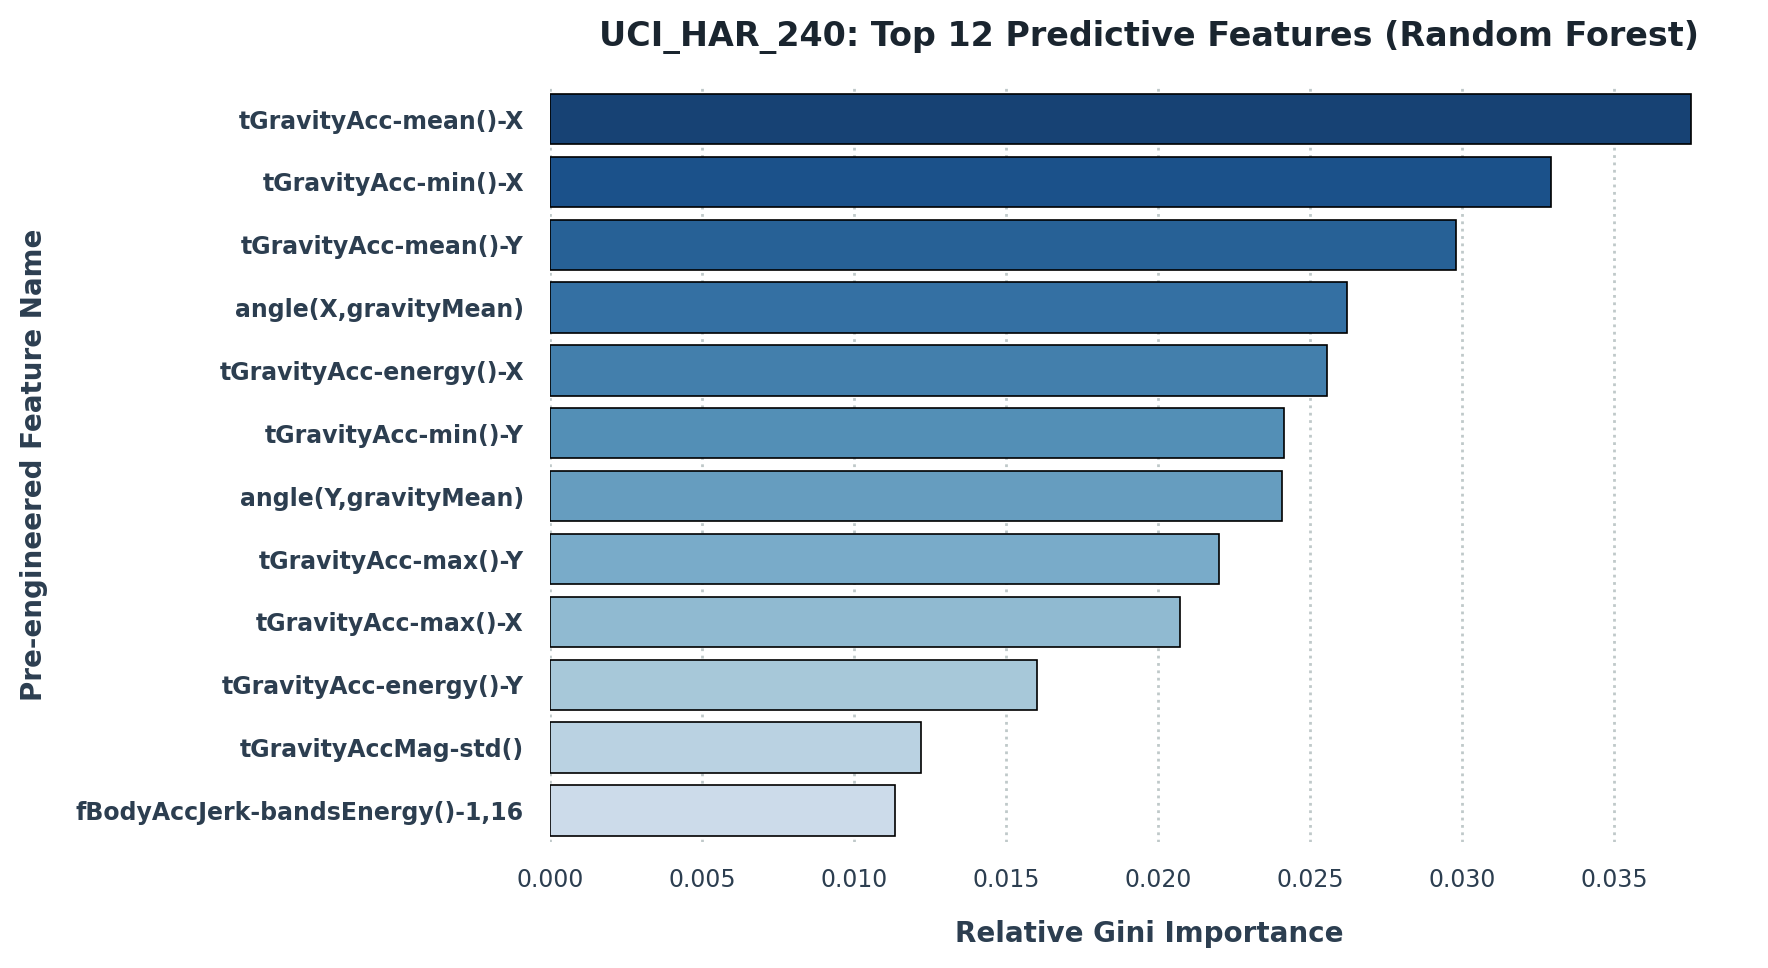

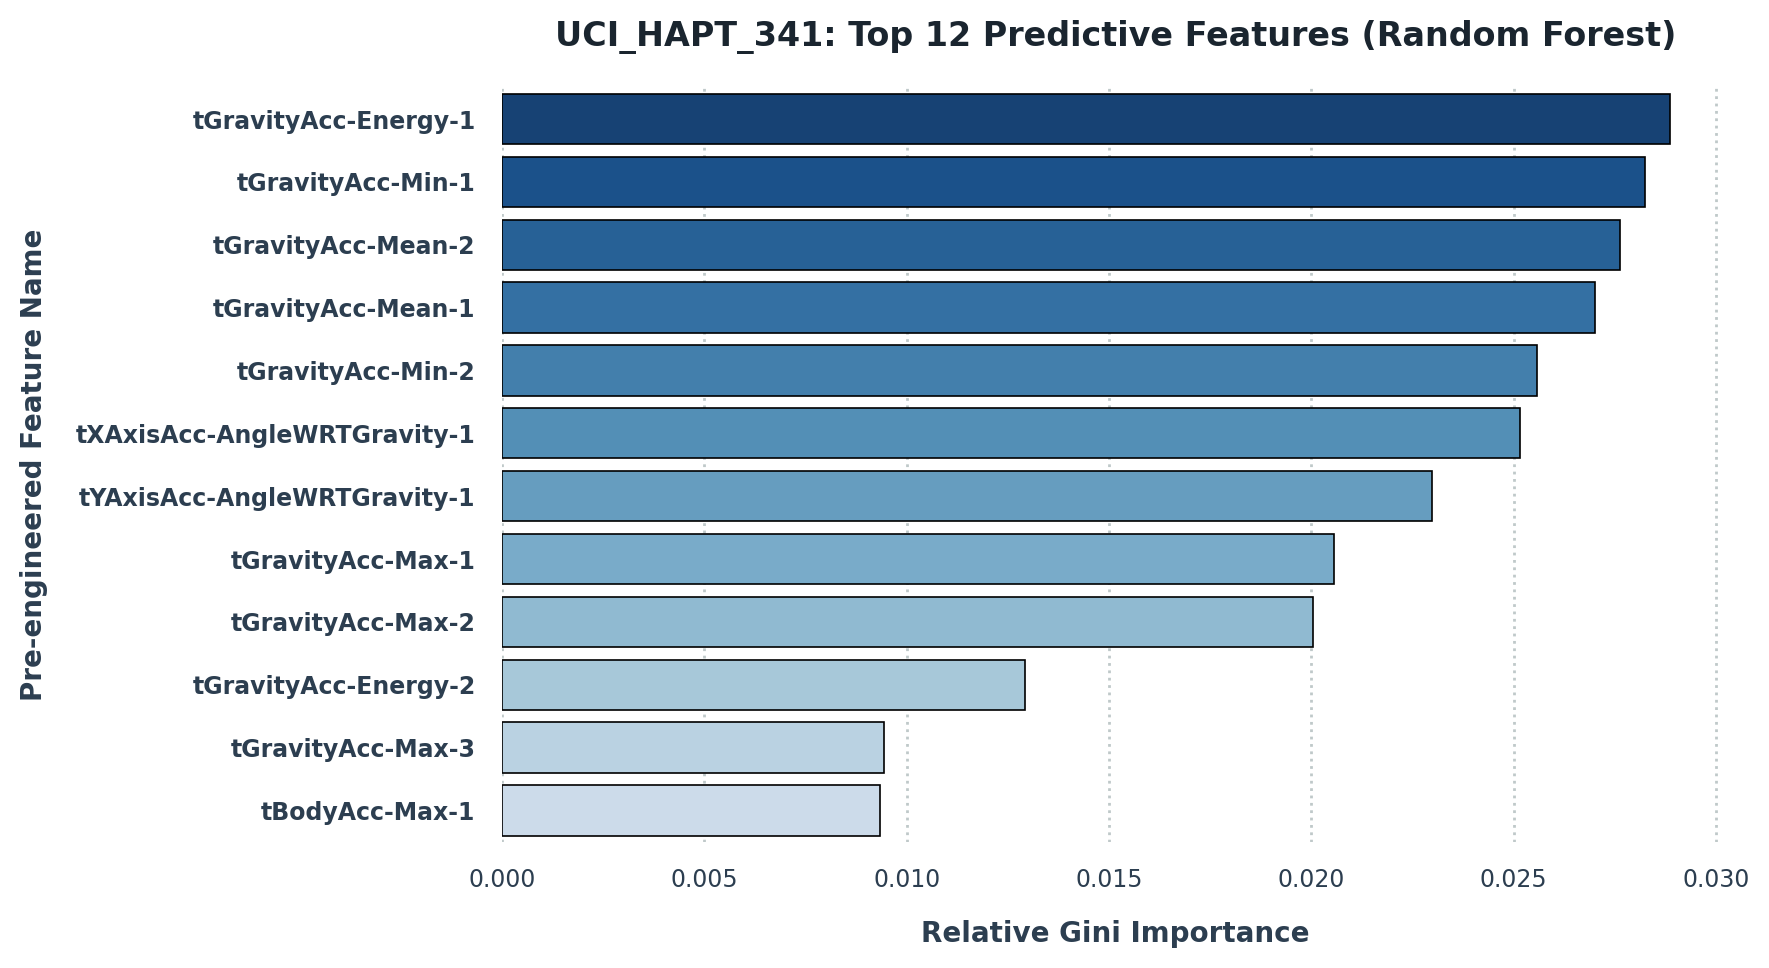

In [50]:
for name, d in loaded.items():
    rf = make_models()["Random Forest"]
    rf.fit(d["X_train"], d["y_train"])
    rf_core = rf.named_steps["model"]
    importances = pd.Series(rf_core.feature_importances_, index=d["X_train"].columns)
    top_features = importances.sort_values(ascending=False).head(12)

    fig, ax = plt.subplots(figsize=(9, 5), dpi=200)

    # Create a nice sequential color palette
    palette = sns.color_palette("Blues_r", n_colors=15)[:12]

    sns.barplot(
        x=top_features.values,
        y=top_features.index,
        hue=top_features.index,
        palette=palette,
        ax=ax,
        edgecolor="black",
        linewidth=0.6,
        legend=False
    )

    ax.set_title(f"{name}: Top 12 Predictive Features (Random Forest)", fontsize=12, fontweight="bold", pad=15, color="#1a252f")
    ax.set_xlabel("Relative Gini Importance", fontsize=10, labelpad=10, fontweight="bold", color="#2c3e50")
    ax.set_ylabel("Pre-engineered Feature Name", fontsize=10, labelpad=10, fontweight="bold", color="#2c3e50")

    plt.xticks(fontsize=8.5, color="#2c3e50")
    plt.yticks(fontsize=8.5, fontweight="semibold", color="#2c3e50")

    sns.despine(left=True, bottom=True)
    ax.grid(axis='x', linestyle=':', alpha=0.6, color='#95a5a6')

    plt.tight_layout()
    plt.show()

## 11. Compare all experiments — KDD: Knowledge presentation

The validation table supports model selection. The final table reports only the selected model's performance on each official test partition. Avoid claiming one dataset is inherently easier based only on accuracy: the number and type of activity classes differ.

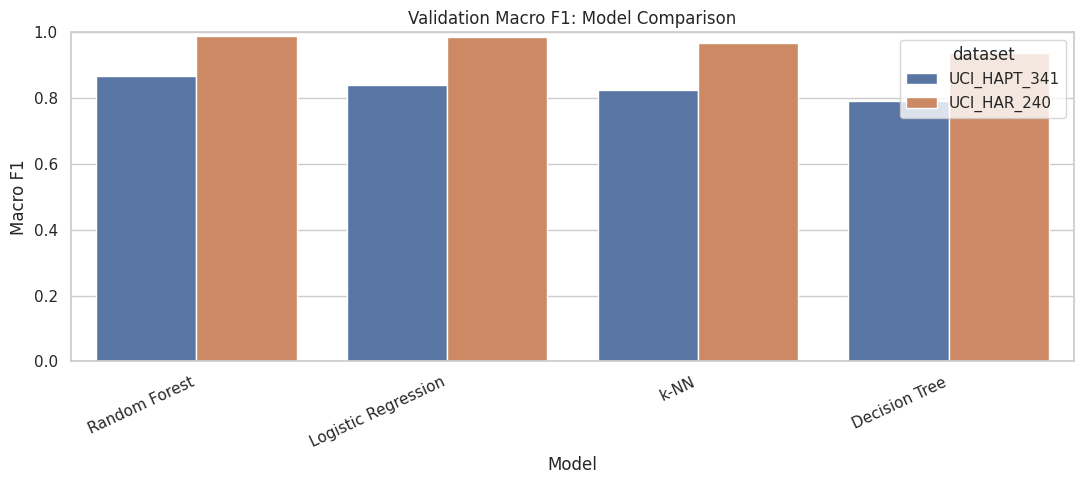

,dataset,model,accuracy,precision_macro,recall_macro,f1_macro
0,UCI_HAR_240,Random Forest,0.928402,0.929351,0.925405,0.926586
1,UCI_HAPT_341,Random Forest,0.911448,0.826434,0.825284,0.822505


In [45]:
if not validation_df.empty:
    plt.figure(figsize=(11, 5))
    sns.barplot(data=validation_df, x="model", y="f1_macro", hue="dataset")
    plt.title("Validation Macro F1: Model Comparison")
    plt.xlabel("Model")
    plt.ylabel("Macro F1")
    plt.xticks(rotation=25, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

if not final_df.empty:
    display(final_df[["dataset", "model", "accuracy", "precision_macro", "recall_macro", "f1_macro"]])


## 12. Save results for the report and GitHub

This section exports the evaluation tables to CSV. The downloaded dataset files remain in the Colab runtime; include source links and dataset citations in your repository README, and only redistribute data in accordance with each dataset's licence/terms.

In [46]:
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

validation_df.to_csv(RESULTS_DIR / "validation_model_comparison.csv", index=False)
final_df.to_csv(RESULTS_DIR / "final_test_results.csv", index=False)

print("Saved:")
print("-", RESULTS_DIR / "validation_model_comparison.csv")
print("-", RESULTS_DIR / "final_test_results.csv")


Saved:
- /content/har_project/results/validation_model_comparison.csv
- /content/har_project/results/final_test_results.csv
